# 02 · 좋은 움직임을 숫자로 — 비용 함수

> 사람이 보는 "좋은 움직임"의 기준을 항 하나하나 숫자로 바꿔 더하면, 컴퓨터가 후보를 비교할 수 있는 비용 함수가 된다.

**지금 위치**

01 상태·입력·모델 → **02 비용** → 03 최적화 → 04 MPC → 05~07 MPPI → 08~09 로봇팔 → 10~13 프로젝트

**이 노트를 끝내면**
1. 목표 오차, 노력(입력 크기), 최종 상태 항이 각각 무엇을 막으려고 있는지 설명할 수 있다.
2. 여러 항을 가중치로 더한 비용 함수 `cart_cost`를 직접 쓰고, 후보들의 비용을 한 번에 계산할 수 있다.
3. 가중치를 바꾸면 "가장 좋은 후보"가 바뀐다는 것을 확인하고, 그 이유를 말할 수 있다.

**필요한 것:** [01](01_state_input_model.ipynb)의 상태 $(p, v)$, 입력 $u$, rollout, 배열 모양 `[K, T]` · **예상 시간:** 30분

## 복습 퀴즈 (01)

<details><summary>1. 1D 카트의 상태와 입력은 각각 무엇인가?</summary>

상태 $x=(p, v)$: 위치와 속도. 입력 $u$: 가속도. 상태는 물리 법칙으로 정해지고, 입력은 우리가 고른다.
</details>

<details><summary>2. 입력열 U의 모양이 [5, 30]이면 cart_rollout의 결과 X의 모양은?</summary>

`[5, 31, 2]`. 후보 5개, 처음 상태 포함 31개 시점, 상태는 (p, v) 두 값.
</details>

<details><summary>3. rollout이란?</summary>

입력열을 모델에 차례로 넣어 미래 상태열을 미리 계산하는 일.
</details>

In [1]:
import numpy as np
from common import setup_plot
from course import cart_rollout, DT     # 01에서 만든 rollout (같은 코드)
plt = setup_plot()
x0 = np.array([0.0, 0.0])               # 정지 상태에서 출발
GOAL = 1.0                              # 목표 위치 1 m
T = 30                                  # horizon 30스텝 = 3초

## 1. 문제 — 후보 다섯 개 중 무엇이 좋은가

01에서는 입력열을 넣어 미래를 계산했다. 이제 카트를 **1 m 지점에 세우는** 입력열 후보 다섯 개가 있다고 하자. 사람이라면 그림을 보고 바로 판단할 수 있다.

| 후보 | 설명 |
|---|---|
| A 딱 맞게 | 2초 동안 가속·감속해 1 m에 선다 |
| B 지나가는 중 | 천천히 가다가 마지막 1초에 가속해, 3초째에 1 m를 **1 m/s로 지나가는 중** |
| C 덜 감 | 0.6 m에서 선다 |
| D 지그재그 | A에 큰 가속·감속을 번갈아 섞었다 |
| E 가만히 | 아무것도 안 한다 |

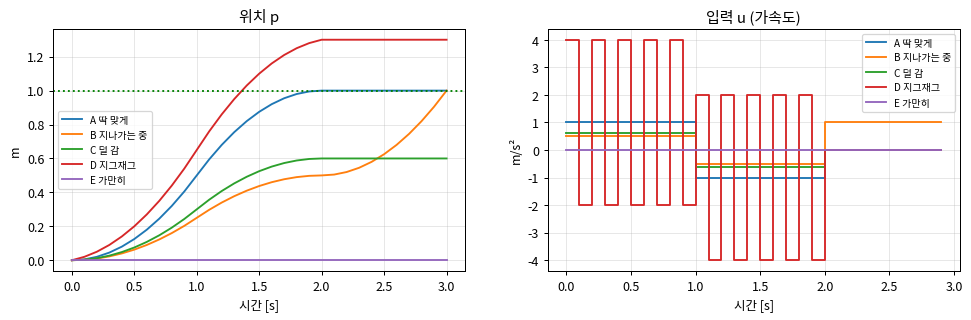

In [2]:
def go(dist, tau):
    # dist[m]를 tau[s] 동안 가속 절반 + 감속 절반으로 가서 서는 입력열
    n = int(round(tau / DT / 2)); a = 4 * dist / tau ** 2
    U = np.zeros(T); U[:n] = a; U[n:2 * n] = -a
    return U

U_A = go(1.0, 2.0)
U_B = go(0.5, 2.0); U_B[20:] = 1.0
U_C = go(0.6, 2.0)
U_D = U_A + np.where(np.arange(T) % 2 == 0, 3.0, -3.0) * (np.arange(T) < 20)
U_E = np.zeros(T)
names = ['A 딱 맞게', 'B 지나가는 중', 'C 덜 감', 'D 지그재그', 'E 가만히']
U_cands = np.stack([U_A, U_B, U_C, U_D, U_E])     # [K=5, T=30]
X_cands = cart_rollout(x0, U_cands)               # [5, 31, 2]

t_x = np.arange(T + 1) * DT
fig, axs = plt.subplots(1, 2, figsize=(13, 3.5))
for k in range(5):
    axs[0].plot(t_x, X_cands[k, :, 0], label=names[k])
    axs[1].step(np.arange(T) * DT, U_cands[k], where='post', label=names[k])
axs[0].axhline(GOAL, color='g', ls=':'); axs[0].set_title('위치 p'); axs[0].set_ylabel('m')
axs[1].set_title('입력 u (가속도)'); axs[1].set_ylabel('m/s²')
for a in axs: a.set_xlabel('시간 [s]'); a.legend(fontsize=8)
plt.show()

**한 번 순위를 매겨 보자.** 아마 A가 1등이고 E가 꼴찌일 것이다. D는 결국 1 m 근처에 가지만 입력이 너무 들쭉날쭉해서 실제 모터라면 덜컹거릴 것이다. B는 3초째 위치만 보면 1 m에 있지만 멈출 생각이 없다.

컴퓨터는 이런 판단을 그림으로 하지 못한다. 후보마다 **숫자 하나**가 있어야 크기를 비교해 고를 수 있다. 이 숫자를 **비용**(cost)이라 하고, 작을수록 좋은 것으로 약속한다. 입력열을 받아 비용을 돌려주는 함수가 **비용 함수**(cost function) $J(U)$다.

이제 사람의 기준을 하나씩 숫자로 바꿔 보자.

## 2. 첫 번째 기준 — 목표에 가까운가 (목표 오차)

### 아이디어
매 시점 목표에서 얼마나 떨어져 있는지 재서 모두 더한다. 오래 멀리 있을수록 비용이 커진다.

$$
J_{\text{goal}} = \sum_{t=1}^{T} (p_t - p_{\text{goal}})^2
$$

말로 하면, 모든 미래 시점의 "목표까지 거리의 제곱"을 더한 것이다.

**왜 제곱인가?**
- 목표보다 앞이든 뒤든(부호와 상관없이) 오차로 센다.
- 멀리 떨어질수록 비용이 훨씬 빨리 커진다. 0.1 m 오차는 0.01, 1 m 오차는 1이다.
- 매끄러운 곡선이라 03 노트의 경사하강(기울기로 내려가기)과 잘 맞는다.

**예측해 보기:** 목표 오차만으로 순위를 매기면 다섯 후보 중 누가 1등일까?

In [3]:
p = X_cands[:, 1:, 0]                        # [5, 30] 시점 1..T의 위치
J_goal = ((p - GOAL) ** 2).sum(axis=1)       # 후보별 합 [5]
for k in np.argsort(J_goal):
    print('%-12s J_goal = %6.2f' % (names[k], J_goal[k]))

D 지그재그       J_goal =   6.96
A 딱 맞게       J_goal =   7.17
C 덜 감        J_goal =  11.94
B 지나가는 중     J_goal =  12.75
E 가만히        J_goal =  30.00


**결과 해석:** 목표 오차만 보면 **D 지그재그가 1등**이다. D는 A보다 조금 더 빨리 목표 근처에 가기 때문이다. 하지만 사람 눈에는 D가 좋은 움직임이 아니다. 기준이 하나 빠져 있다는 뜻이다.

## 3. 두 번째 기준 — 힘을 아껴 쓰는가 (노력)

### 문제
D는 매 스텝 ±3 m/s²를 번갈아 쓴다. 실제 모터에 이런 명령을 주면 진동이 생기고 에너지도 많이 든다. 목표 오차만 보는 비용 함수는 이것을 전혀 문제 삼지 않는다.

### 아이디어
입력의 크기에도 비용을 매긴다. 큰 가속도를 쓸수록 비용이 커지게 한다.

$$
J_{\text{effort}} = \sum_{t=0}^{T-1} u_t^2
$$

그리고 두 항을 **가중치**(weight) $w$로 섞어 더한다.

$$
J = w_{\text{goal}} J_{\text{goal}} + w_u J_{\text{effort}}
$$

가중치는 "어느 기준을 얼마나 중요하게 볼지"를 정하는 손잡이다. 여기서는 $w_{\text{goal}}=1,\ w_u=0.01$로 둔다.

In [4]:
J_effort = (U_cands ** 2).sum(axis=1)
w_goal, w_u = 1.0, 0.01
J2 = w_goal * J_goal + w_u * J_effort
print('%-12s %8s %9s %10s' % ('후보', 'J_goal', 'J_effort', 'J(합)'))
for k in np.argsort(J2):
    print('%-12s %8.2f %9.1f %10.2f' % (names[k], J_goal[k], J_effort[k], J2[k]))

후보             J_goal  J_effort       J(합)
A 딱 맞게           7.17      20.0       7.37
D 지그재그           6.96     200.0       8.96
C 덜 감           11.94       7.2      12.01
B 지나가는 중        12.75      15.0      12.90
E 가만히           30.00       0.0      30.00


**결과 해석:** D의 노력 비용(200)이 A(20)의 10배라서, 합치면 **A가 1등**이 된다. 기준을 하나 더했더니 사람의 판단과 가까워졌다.

## 4. 세 번째 기준 — 끝에 목표에 서 있는가 (최종 상태)

### 문제
B를 보자. 3초째(horizon 끝)에 정확히 1 m에 있다. 하지만 속도가 1 m/s라서 계속 달려간다. 우리가 계산한 비용은 horizon 안(3초까지)만 본다. **horizon이 끝난 뒤에 벌어질 일**은 비용에 들어가지 않는다.

아래는 모든 후보에 입력 0을 2초 더 넣어, horizon 다음을 이어서 그려 본 것이다.

horizon 끝 상태 (p, v):
  A 딱 맞게       p=1.00 m, v=0.00 m/s  → 2초 뒤 p=1.00 m
  B 지나가는 중     p=1.00 m, v=1.00 m/s  → 2초 뒤 p=3.00 m
  C 덜 감        p=0.60 m, v=0.00 m/s  → 2초 뒤 p=0.60 m
  D 지그재그       p=1.30 m, v=0.00 m/s  → 2초 뒤 p=1.30 m
  E 가만히        p=0.00 m, v=0.00 m/s  → 2초 뒤 p=0.00 m


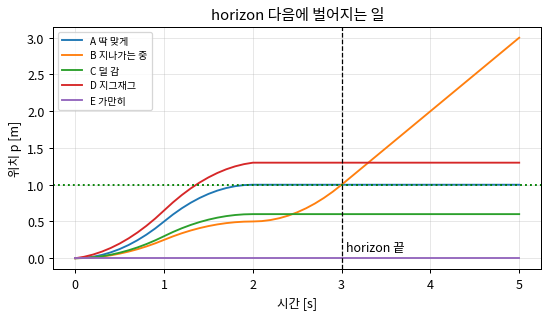

In [5]:
U_ext = np.concatenate([U_cands, np.zeros((5, 20))], axis=1)   # 2초 동안 u=0 추가
X_ext = cart_rollout(x0, U_ext)
t_ext = np.arange(U_ext.shape[1] + 1) * DT

plt.figure(figsize=(7, 3.5))
for k in range(5):
    plt.plot(t_ext, X_ext[k, :, 0], label=names[k])
plt.axvline(T * DT, color='k', ls='--', lw=1); plt.text(T * DT + 0.05, 0.1, 'horizon 끝')
plt.axhline(GOAL, color='g', ls=':')
plt.xlabel('시간 [s]'); plt.ylabel('위치 p [m]'); plt.legend(fontsize=8)
plt.title('horizon 다음에 벌어지는 일'); plt.show()
print('horizon 끝 상태 (p, v):')
for k in range(5):
    print('  %-12s p=%.2f m, v=%.2f m/s  → 2초 뒤 p=%.2f m' % (names[k], X_cands[k, -1, 0], X_cands[k, -1, 1], X_ext[k, -1, 0]))

**결과 해석:** B는 horizon 끝에서 1 m에 있지만, 2초 뒤에는 3 m까지 가 버린다. horizon 안만 보는 비용은 이것을 놓친다.

### 아이디어
horizon **마지막 시점의 상태**에 따로 비용을 매긴다. 이것을 **최종 비용**(terminal cost)이라 한다.
- 마지막 위치가 목표에서 벗어난 만큼: $w_{\text{term}} (p_T - p_{\text{goal}})^2$
- 마지막 속도가 0이 아닌 만큼: $w_{v,\text{term}}\, v_T^2$ ("끝에는 멈춰 있어라")

마지막 시점을 따로 강조하는 이유는, 그 상태가 horizon 너머의 미래를 대신 말해 주기 때문이다. 끝에 목표에 멈춰 있으면 그 뒤에도 거기 있을 것이다.

## 5. 모두 합친 비용 함수 `cart_cost`

$$
J(U) = \sum_{t=1}^{T}\Big[w_{\text{goal}}(p_t-p_{\text{goal}})^2\Big] + \sum_{t=0}^{T-1} w_u u_t^2 + w_{\text{term}}(p_T-p_{\text{goal}})^2 + w_{v,\text{term}}\, v_T^2
$$

말로 하면: (매 시점 목표 오차) + (매 시점 노력) + (마지막 위치 오차) + (마지막 속도).

기본 가중치는 $w_{\text{goal}}=1,\ w_u=0.01,\ w_{\text{term}}=10,\ w_{v,\text{term}}=1$로 둔다. 01의 rollout처럼 후보 여러 개(`[K, T]`)도 한 번에 계산되도록 `...`을 쓴다.

In [6]:
def cart_cost(X, U, goal=1.0, w_goal=1.0, w_u=0.01, w_term=10.0, w_vterm=1.0):
    # X[..., T+1, 2], U[..., T] -> 후보별 비용 J[...]
    p, v = X[..., 1:, 0], X[..., -1, 1]
    running = w_goal * (p - goal) ** 2 + w_u * U ** 2           # 시점별 비용
    return running.sum(-1) + w_term * (p[..., -1] - goal) ** 2 + w_vterm * v ** 2

J = cart_cost(X_cands, U_cands)
J_noterm = cart_cost(X_cands, U_cands, w_term=0.0, w_vterm=0.0)
print('%-12s %14s %14s' % ('후보', '최종 항 없이', '최종 항 포함'))
for k in np.argsort(J):
    print('%-12s %14.2f %14.2f' % (names[k], J_noterm[k], J[k]))

후보                  최종 항 없이        최종 항 포함
A 딱 맞게                 7.37           7.37
D 지그재그                 8.96           9.86
C 덜 감                 12.01          13.61
B 지나가는 중              12.90          13.90
E 가만히                 30.00          40.00


**결과 해석:**
- 최종 항을 넣으면 B의 비용이 1 늘고(끝 속도 1 m/s → $1\times1^2$), 끝 위치가 목표와 다른 D(1.3 m)·C(0.6 m)·E(0 m)도 늘어난다(끝 위치 오차² × 10). 끝에 목표에 멈춰 있는 A만 그대로다.
- 이 다섯 후보에서는 최종 항을 넣어도 순위가 바뀌지 않았다. 하지만 B가 "끝 속도 때문에" 비용을 더 받는다는 것은 숫자로 확인할 수 있다. 04 노트의 MPC처럼 horizon이 짧을수록 이 항이 중요해진다. horizon 너머를 볼 방법이 이것밖에 없기 때문이다.

`cart_cost`는 `course.py`에 같은 코드로 저장해 두었다.

**한 문장으로:** 최종 비용이 왜 필요한지 "horizon"이라는 말을 넣어 설명해 보자.

## 6. 가중치를 바꾸면 최선이 바뀐다

### 문제
가중치는 누가 정할까? 정답이 있을까?

### 아이디어
가중치는 **무엇을 더 중요하게 여기는지에 대한 선택**이다. 같은 후보들이라도 가중치가 바뀌면 1등이 바뀐다. 이것을 보기 위해 "1 m를 $\tau$초 만에 가서 서는" 후보를 $\tau$=0.8~3초로 여러 개 만든다. 빨리 갈수록 큰 가속도가 필요하다.

**예측해 보기:** 노력 가중치 $w_u$를 크게 하면 빨리 가는 후보($\tau$ 작음)와 천천히 가는 후보($\tau$ 큼) 중 어느 쪽이 유리해질까?

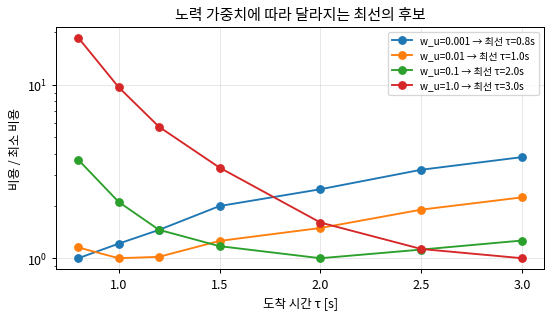

In [7]:
taus = np.array([0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0])
U_fam = np.stack([go(1.0, tau) for tau in taus])      # [7, T]
X_fam = cart_rollout(x0, U_fam)

plt.figure(figsize=(7, 3.5))
for w in [0.001, 0.01, 0.1, 1.0]:
    J_fam = cart_cost(X_fam, U_fam, w_u=w)
    best = taus[J_fam.argmin()]
    plt.plot(taus, J_fam / J_fam.min(), 'o-', label=f'w_u={w} → 최선 τ={best}s')
plt.xlabel('도착 시간 τ [s]'); plt.ylabel('비용 / 최소 비용')
plt.yscale('log'); plt.legend(fontsize=8); plt.title('노력 가중치에 따라 달라지는 최선의 후보')
plt.show()

**결과 해석:** $w_u$가 작으면(0.001) 힘을 많이 써도 손해가 적으니 가장 빨리 가는 0.8초가 최선이다. $w_u$가 커질수록 최선이 1.0초 → 2.0초 → 3.0초로 느려진다. "빨리 가기"와 "힘 아끼기"가 서로 부딪히는데, 가중치가 둘 사이의 **절충점**(trade-off)을 정한다.

정답 가중치는 없다. 로봇이 할 일과 안전 기준에 맞춰 사람이 정하고, 결과를 보며 조정한다(튜닝).

**직접 해보기:** `w_term`을 0으로 바꾸고 다시 실행해 보자. 최선 τ가 바뀌는지 살펴보자.
<details><summary>무엇이 달라지나</summary>

이 후보들은 모두 끝에 목표에 멈추므로 최종 항이 0이다. 그래서 `w_term`을 바꿔도 결과가 같다. 최종 항은 끝 상태가 다른 후보들을 구별할 때만 효과가 있다.
</details>

## 7. 맛보기 — "넘으면 안 되는 것"도 비용으로

### 문제
카트 속도가 1 m/s를 넘으면 위험하다고 하자. 이런 규칙(제약)은 어떻게 넣을까?

### 아이디어
가장 쉬운 방법은 **규칙을 어긴 만큼 큰 비용**을 주는 것이다. 속도가 1 m/s 이하면 0이고, 넘은 만큼 제곱해서 크게 더한다.

$$
J_{\text{speed}} = w_{\text{speed}} \sum_t \max(0,\ |v_t| - v_{\max})^2
$$

이렇게 비용으로 넣는 규칙을 **soft 제약**(soft constraint)이라 한다. "절대 넘지 마라"가 아니라 "넘으면 많이 손해다"라는 뜻이다. 다른 이득이 충분히 크면 넘을 수도 있다는 점을 기억해 두자. 이 성질은 06 노트(장애물)와 11 노트(손 충돌 비용)에서 다시 중요해진다.

In [8]:
def speed_penalty(X, v_max=1.0, w_speed=100.0):
    v = X[..., 1:, 1]
    return w_speed * (np.maximum(0.0, np.abs(v) - v_max) ** 2).sum(-1)

peak_speed = X_fam[:, :, 1].max(axis=1)
J_plain = cart_cost(X_fam, U_fam)
J_soft = J_plain + speed_penalty(X_fam)
print('%6s %10s %10s %12s' % ('τ [s]', '최고속도', '기본 J', 'soft 제약 J'))
for tau, vp, a, b in zip(taus, peak_speed, J_plain, J_soft):
    print('%6.1f %9.2f %10.2f %12.2f' % (tau, vp, a, b))
print('최선 τ: 기본 %.1fs → soft 제약 포함 %.1fs' % (taus[J_plain.argmin()], taus[J_soft.argmin()]))

 τ [s]       최고속도       기본 J    soft 제약 J
   0.8      2.50       5.69       396.32
   1.0      2.00       4.93       184.93
   1.2      1.67       5.03        82.19
   1.5      1.42       6.21        36.87
   2.0      1.00       7.37         7.37
   2.5      0.77       9.40         9.40
   3.0      0.67      11.06        11.06
최선 τ: 기본 1.0s → soft 제약 포함 2.0s


**결과 해석:** 기본 비용으로는 최고속도 2 m/s인 1.0초 후보가 최선이었다. 속도 제한 비용을 넣으면 1 m/s를 넘는 후보들의 비용이 크게 뛰고, 최고속도가 정확히 1 m/s인 τ=2.0초 후보가 최선이 된다. 규칙을 비용으로 바꾸는 이 방식이 이 시리즈 전체에서 장애물·관절 한계·충돌을 다루는 방법이다.

## 핵심 정리

- 비용 함수 $J(U)$는 후보 입력열을 숫자 하나로 바꾼다. 작을수록 좋다. 컴퓨터는 이 숫자로 후보를 비교한다.
- 사람의 기준을 **항**으로 하나씩 바꿔 더한다: 목표 오차(가까이), 노력(부드럽게), 최종 상태(끝에 멈춰서).
- **최종 비용**은 horizon 너머를 대신 보는 장치다.
- **가중치**는 기준 사이의 절충을 정한다. 가중치가 바뀌면 최선의 후보가 바뀐다.
- 넘으면 안 되는 규칙도 **soft 제약**(어긴 만큼 비용)으로 넣을 수 있다. 다만 절대 금지는 아니다.

## 확인 문제

<details><summary>1. 목표 오차만 쓰면 어떤 후보가 뽑힐 위험이 있나?</summary>

입력을 아무리 크고 들쭉날쭉하게 써도 목표에 조금이라도 빨리 가는 후보(D처럼). 노력 항이 이를 막는다.
</details>

<details><summary>2. horizon 3초인 비용 함수가 "3초째에 1 m를 2 m/s로 지나가는" 후보를 막으려면 어떤 항이 필요한가?</summary>

최종 속도 항 $w_{v,\text{term}} v_T^2$. 끝 상태가 멈춰 있도록 요구한다.
</details>

<details><summary>3. w_u를 10배로 키우면 로봇의 움직임은 어떻게 변할까?</summary>

힘을 쓰는 것이 더 비싸지므로 가속도를 작게 쓰고, 목표에 더 천천히 간다.
</details>

<details><summary>4. 속도 제한을 soft 제약으로 넣었다. 속도가 제한을 절대 넘지 않는다고 보장할 수 있나?</summary>

없다. 넘은 만큼 비용이 커질 뿐이라, 다른 항의 이득이 더 크면 넘는 후보가 최선이 될 수 있다.
</details>

## 실제 프로젝트에서는

cuRobo의 MPPI도 같은 구조의 비용 함수를 쓴다. 설정 파일 `~/curobo/src/curobo/content/configs/task/particle_mpc.yml`의 `cost:` 블록에 항과 가중치가 있다.

| 이 노트 | cuRobo 비용 항 | 가중치 (yml) |
|---|---|---|
| 목표 오차 + 최종 위치 | `pose_cfg` (손끝 위치·자세 목표) | `[60, 300, 20, 20]` |
| soft 제약 (속도 제한) | `bound_cfg` (관절 위치·속도·가속도 한계) | 5000 |
| 끝에 멈춰라 (비슷한 역할) | `stop_cfg` (horizon 안에 멈출 수 없는 과속 억제) | 100 |
| (06에서 배움) 장애물 | `primitive_collision_cfg` (환경 충돌) | 100000 |
| (08에서 배움) 자기 충돌 | `self_collision_cfg` | 50000 |

충돌 가중치가 100000으로 매우 크다. 그래도 soft 제약이라는 점은 같다(06, 11 노트).

## 다음 노트

[03 · 가장 좋은 행동열 찾기](03_optimization.ipynb): 이번에는 후보 몇 개를 비교했다. 하지만 가능한 입력열은 무한히 많다. 비용이 가장 작은 입력열을 컴퓨터가 직접 찾게 하는 방법(최적화)을 배운다.